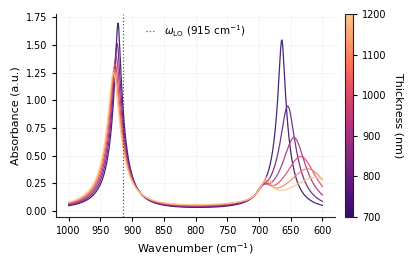

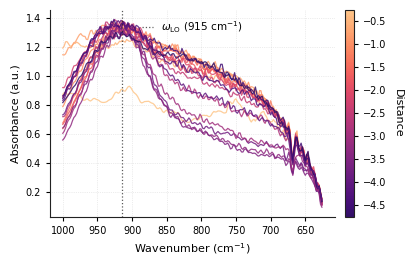

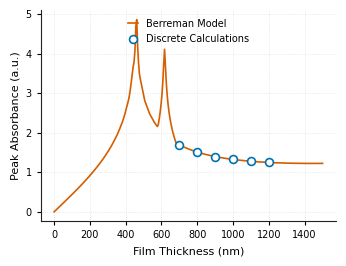

In [2]:
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np


def load_spectrum_txt(file_path):
    
    for delimiter in [None, ",", "\t", ";"]:
        try:
            data = np.genfromtxt(file_path, delimiter=delimiter, comments="#")
            data = data[~np.isnan(data).any(axis=1)]
            if data.ndim == 2 and data.shape[1] >= 2:
                x, y = data[:, 0], data[:, 1]
                mask = (x >= 600) & (x <= 1000)
                x_sub, y_sub = x[mask], y[mask]
                order = np.argsort(x_sub)
                return x_sub[order], y_sub[order]
        except Exception:
            continue
    return None, None


def run_berreman_model(
    data_folder=r"/drive/notebooks/20926/simulation",
    save_prefix="berreman",
):
    
    wn = np.linspace(600, 1000, 1000)

    # --- Film & Substrate Parameters ---
    w_TO = 700.0  # TO phonon frequency (cm^-1)
    w_LO = 915.0  # LO phonon frequency (cm^-1)
    gamma_film = 20.0  # Damping constant (cm^-1)
    eps_inf = 4.0  # High-frequency dielectric constant

    # Dielectric function of polar film
    eps_film = eps_inf * (
        1.0
        + (w_LO**2 - w_TO**2) / (w_TO**2 - wn**2 - 1j * gamma_film * wn)
    )

    # Drude dielectric function of Au substrate
    wp_Au = 72500.0
    gamma_Au = 400.0
    eps_Au = 1.0 - (wp_Au**2) / (wn**2 + 1j * gamma_Au * wn)

    theta_deg = 50.0
    theta_0 = np.radians(theta_deg)
    sin_sq = np.sin(theta_0) ** 2

    kz0 = 2 * np.pi * wn * np.sqrt(1.0 - sin_sq + 0j)
    kz1 = 2 * np.pi * wn * np.sqrt(eps_film - sin_sq)
    kz2 = 2 * np.pi * wn * np.sqrt(eps_Au - sin_sq)

    kz1 = np.where(np.imag(kz1) < 0, -kz1, kz1)
    kz2 = np.where(np.imag(kz2) < 0, -kz2, kz2)

    # Fresnel reflection coefficients (p-polarization)
    r01 = (eps_film * kz0 - 1.0 * kz1) / (eps_film * kz0 + 1.0 * kz1)
    r12 = (eps_Au * kz1 - eps_film * kz2) / (eps_Au * kz1 + eps_film * kz2)
    r02 = (eps_Au * kz0 - 1.0 * kz2) / (eps_Au * kz0 + 1.0 * kz2)

    R_ref = np.abs(r02) ** 2

    def compute_absorbance(d_nm):
        d_cm = d_nm * 1e-7
        phase = np.exp(2j * kz1 * d_cm)
        r_total = (r01 + r12 * phase) / (1.0 + r01 * r12 * phase)
        R_film = np.abs(r_total) ** 2
        return -np.log10(R_film / R_ref)

    thicknesses_nm = [700, 800, 900, 1000, 1100, 1200]

    spectra = {}
    discrete_peaks = []
    for d_nm in thicknesses_nm:
        abs_spectrum = compute_absorbance(d_nm)
        spectra[d_nm] = abs_spectrum
        peak_idx = np.argmax(abs_spectrum)
        discrete_peaks.append((d_nm, abs_spectrum[peak_idx]))

    sweep_thickness_nm = np.linspace(1, 1500, 300)
    sweep_max_abs = [np.max(compute_absorbance(d)) for d in sweep_thickness_nm]

    exp_files = sorted(glob.glob(os.path.join(data_folder, "*.txt")))

    # --- Unified Publication Style Configuration ---
    rc_publication = {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8.5,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "axes.linewidth": 0.8,
        "axes.edgecolor": "#222222",
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 3.0,
        "xtick.major.width": 0.8,
        "ytick.major.size": 3.0,
        "ytick.major.width": 0.8,
    }

    with mpl.rc_context(rc_publication):
        # Create a reusable colormap logic to avoid stark black/white bounds
        magma_cmap = plt.get_cmap("magma")
        trunc_magma = mpl.colors.LinearSegmentedColormap.from_list(
            "trunc_magma", magma_cmap(np.linspace(0.18, 0.88, 256))
        )

        fig1, ax1 = plt.subplots(figsize=(4.2, 2.7))
        
        
        vmin_sim, vmax_sim = min(thicknesses_nm), max(thicknesses_nm)
        norm_sim = mpl.colors.Normalize(vmin=vmin_sim, vmax=vmax_sim)
        sm_sim = plt.cm.ScalarMappable(cmap=trunc_magma, norm=norm_sim)
        sm_sim.set_array([])

        for d_nm in thicknesses_nm:
            color = trunc_magma(norm_sim(d_nm))
            ax1.plot(
                wn,
                spectra[d_nm],
                color=color,
                linewidth=0.9,
                alpha=0.9,
            )

        # Plot LO Phonon reference line
        ax1.axvline(
            w_LO,
            color="#222222",
            linestyle=":",
            linewidth=0.9,
            alpha=0.75,
            label=rf"$\omega_{{\mathrm{{LO}}}}$ ({w_LO:.0f} $\mathrm{{cm^{{-1}}}}$)",
        )

        ax1.invert_xaxis()
        ax1.set_xlabel(r"Wavenumber ($\mathrm{cm^{-1}}$)")
        ax1.set_ylabel("Absorbance (a.u.)")
        ax1.spines["top"].set_visible(False)
        ax1.spines["right"].set_visible(False)
        ax1.grid(True, linestyle=":", linewidth=0.5, color="#CCCCCC", alpha=0.7)

        ax1.legend(
            frameon=False,
            loc="upper center",
            fontsize=7.5,
            handlelength=0.9,
        )

        cbar_sim = fig1.colorbar(sm_sim, ax=ax1, pad=0.03, aspect=25)
        cbar_sim.set_label("Thickness (nm)", rotation=270, labelpad=12, fontsize=8)
        cbar_sim.ax.tick_params(labelsize=7)

        plt.tight_layout()
        if save_prefix:
            fig1.savefig(
                f"{save_prefix}_simulated_profiles.pdf",
                format="pdf",
                bbox_inches="tight",
                pad_inches=0.04,
            )
        plt.show()

        
        fig2, ax2 = plt.subplots(figsize=(4.2, 2.7))
        if exp_files:
            exp_val_dict = {}
            for fpath in exp_files:
                fname = os.path.basename(fpath).replace(".txt", "")
                try:
                    val = float(fname)
                except ValueError:
                    val = 0.0 
                exp_val_dict[fpath] = val

            exp_vals = list(exp_val_dict.values())
            vmin_exp, vmax_exp = min(exp_vals), max(exp_vals)
            
            if vmin_exp == vmax_exp: 
                vmax_exp += 1.0
                
            norm_exp = mpl.colors.Normalize(vmin=vmin_exp, vmax=vmax_exp)
            sm_exp = plt.cm.ScalarMappable(cmap=trunc_magma, norm=norm_exp)
            sm_exp.set_array([])

            for fpath in exp_files:
                val = exp_val_dict[fpath]
                color = trunc_magma(norm_exp(val))
                x_data, y_data = load_spectrum_txt(fpath)
                
                if x_data is not None and len(x_data) > 0:
                    ax2.plot(
                        x_data,
                        y_data,
                        color=color,
                        linewidth=0.9,
                        alpha=0.85,
                    )

            ax2.axvline(
                w_LO,
                color="#222222",
                linestyle=":",
                linewidth=0.9,
                alpha=0.75,
                label=rf"$\omega_{{\mathrm{{LO}}}}$ ({w_LO:.0f} $\mathrm{{cm^{{-1}}}}$)",
            )

         
            ax2.legend(
                frameon=False,
                loc="upper center",
                fontsize=7.5,
                handlelength=1.0,
            )
            
        
            cbar_exp = fig2.colorbar(sm_exp, ax=ax2, pad=0.03, aspect=25)
            cbar_exp.set_label("Distance", rotation=270, labelpad=12, fontsize=8)
            cbar_exp.ax.tick_params(labelsize=7)

        else:
            ax2.text(
                0.5,
                0.5,
                f"No spectra files found in:\n{data_folder}",
                ha="center",
                va="center",
                transform=ax2.transAxes,
                fontsize=7.5,
                color="#D55E00",
            )

        ax2.invert_xaxis()
        ax2.set_xlabel(r"Wavenumber ($\mathrm{cm^{-1}}$)")
        ax2.set_ylabel("Absorbance (a.u.)")
        ax2.spines["top"].set_visible(False)
        ax2.spines["right"].set_visible(False)
        ax2.grid(True, linestyle=":", linewidth=0.5, color="#CCCCCC", alpha=0.7)

        plt.tight_layout()
        if save_prefix:
            fig2.savefig(
                f"{save_prefix}_experimental_spectra.pdf",
                format="pdf",
                bbox_inches="tight",
                pad_inches=0.04,
            )
        plt.show()


        fig3, ax3 = plt.subplots(figsize=(3.5, 2.7))
        disc_d, disc_val = zip(*discrete_peaks)

        ax3.plot(
            sweep_thickness_nm,
            sweep_max_abs,
            color="#D55E00",
            linewidth=1.2,
            label="Berreman Model",
            zorder=2,
        )

        ax3.scatter(
            disc_d,
            disc_val,
            facecolor="white",
            edgecolor="#0072B2",
            linewidth=1.2,
            s=32,
            label="Discrete Calculations",
            zorder=3,
        )

        ax3.set_xlabel("Film Thickness (nm)")
        ax3.set_ylabel("Peak Absorbance (a.u.)")
        ax3.spines["top"].set_visible(False)
        ax3.spines["right"].set_visible(False)
        ax3.grid(True, linestyle=":", linewidth=0.5, color="#CCCCCC", alpha=0.7)

        # Moved to upper center
        ax3.legend(
            frameon=False, 
            loc="upper center", 
            ncol=1, 
            fontsize=7.0, 
            handlelength=1.1
        )

        plt.tight_layout()
        if save_prefix:
            fig3.savefig(
                f"{save_prefix}_thickness_trend.pdf",
                format="pdf",
                bbox_inches="tight",
                pad_inches=0.04,
            )
        plt.show()

# Example execution:
if __name__ == "__main__":
    run_berreman_model()

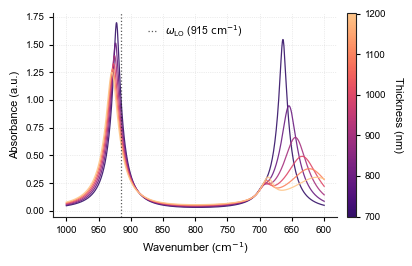

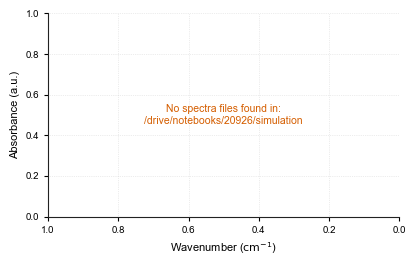

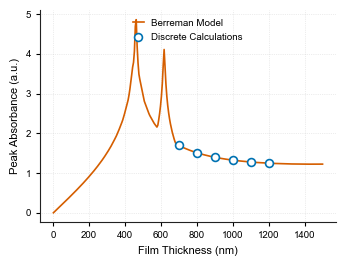

In [1]:
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np


def load_spectrum_txt(file_path):
    
    for delimiter in [None, ",", "\t", ";"]:
        try:
            data = np.genfromtxt(file_path, delimiter=delimiter, comments="#")
            data = data[~np.isnan(data).any(axis=1)]
            if data.ndim == 2 and data.shape[1] >= 2:
                x, y = data[:, 0], data[:, 1]
                mask = (x >= 600) & (x <= 1000)
                x_sub, y_sub = x[mask], y[mask]
                order = np.argsort(x_sub)
                return x_sub[order], y_sub[order]
        except Exception:
            continue
    return None, None


def run_berreman_model(
    data_folder=r"/drive/notebooks/20926/simulation",
    save_prefix="berreman",
):
    
    wn = np.linspace(600, 1000, 1000)

    # --- Film & Substrate Parameters ---
    w_TO = 700.0  # TO phonon frequency (cm^-1)
    w_LO = 915.0  # LO phonon frequency (cm^-1)
    gamma_film = 20.0  # Damping constant (cm^-1)
    eps_inf = 4.0  # High-frequency dielectric constant

    # Dielectric function of polar film
    eps_film = eps_inf * (
        1.0
        + (w_LO**2 - w_TO**2) / (w_TO**2 - wn**2 - 1j * gamma_film * wn)
    )

    # Drude dielectric function of Au substrate
    wp_Au = 72500.0
    gamma_Au = 400.0
    eps_Au = 1.0 - (wp_Au**2) / (wn**2 + 1j * gamma_Au * wn)

    theta_deg = 50.0
    theta_0 = np.radians(theta_deg)
    sin_sq = np.sin(theta_0) ** 2

    kz0 = 2 * np.pi * wn * np.sqrt(1.0 - sin_sq + 0j)
    kz1 = 2 * np.pi * wn * np.sqrt(eps_film - sin_sq)
    kz2 = 2 * np.pi * wn * np.sqrt(eps_Au - sin_sq)

    kz1 = np.where(np.imag(kz1) < 0, -kz1, kz1)
    kz2 = np.where(np.imag(kz2) < 0, -kz2, kz2)

    # Fresnel reflection coefficients (p-polarization)
    r01 = (eps_film * kz0 - 1.0 * kz1) / (eps_film * kz0 + 1.0 * kz1)
    r12 = (eps_Au * kz1 - eps_film * kz2) / (eps_Au * kz1 + eps_film * kz2)
    r02 = (eps_Au * kz0 - 1.0 * kz2) / (eps_Au * kz0 + 1.0 * kz2)

    R_ref = np.abs(r02) ** 2

    def compute_absorbance(d_nm):
        d_cm = d_nm * 1e-7
        phase = np.exp(2j * kz1 * d_cm)
        r_total = (r01 + r12 * phase) / (1.0 + r01 * r12 * phase)
        R_film = np.abs(r_total) ** 2
        return -np.log10(R_film / R_ref)

    thicknesses_nm = [700, 800, 900, 1000, 1100, 1200]

    spectra = {}
    discrete_peaks = []
    for d_nm in thicknesses_nm:
        abs_spectrum = compute_absorbance(d_nm)
        spectra[d_nm] = abs_spectrum
        peak_idx = np.argmax(abs_spectrum)
        discrete_peaks.append((d_nm, abs_spectrum[peak_idx]))

    sweep_thickness_nm = np.linspace(1, 1500, 300)
    sweep_max_abs = [np.max(compute_absorbance(d)) for d in sweep_thickness_nm]

    exp_files = sorted(glob.glob(os.path.join(data_folder, "*.txt")))

    # --- Unified Publication Style Configuration ---
    rc_publication = {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8.5,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "axes.linewidth": 0.8,
        "axes.edgecolor": "#222222",
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 3.0,
        "xtick.major.width": 0.8,
        "ytick.major.size": 3.0,
        "ytick.major.width": 0.8,
    }

    with mpl.rc_context(rc_publication):
        # Create a reusable colormap logic to avoid stark black/white bounds
        magma_cmap = plt.get_cmap("magma")
        trunc_magma = mpl.colors.LinearSegmentedColormap.from_list(
            "trunc_magma", magma_cmap(np.linspace(0.18, 0.88, 256))
        )

        fig1, ax1 = plt.subplots(figsize=(4.2, 2.7))
        
        
        vmin_sim, vmax_sim = min(thicknesses_nm), max(thicknesses_nm)
        norm_sim = mpl.colors.Normalize(vmin=vmin_sim, vmax=vmax_sim)
        sm_sim = plt.cm.ScalarMappable(cmap=trunc_magma, norm=norm_sim)
        sm_sim.set_array([])

        for d_nm in thicknesses_nm:
            color = trunc_magma(norm_sim(d_nm))
            ax1.plot(
                wn,
                spectra[d_nm],
                color=color,
                linewidth=0.9,
                alpha=0.9,
            )

        # Plot LO Phonon reference line
        ax1.axvline(
            w_LO,
            color="#222222",
            linestyle=":",
            linewidth=0.9,
            alpha=0.75,
            label=rf"$\omega_{{\mathrm{{LO}}}}$ ({w_LO:.0f} $\mathrm{{cm^{{-1}}}}$)",
        )

        ax1.invert_xaxis()
        ax1.set_xlabel(r"Wavenumber ($\mathrm{cm^{-1}}$)")
        ax1.set_ylabel("Absorbance (a.u.)")
        ax1.spines["top"].set_visible(False)
        ax1.spines["right"].set_visible(False)
        ax1.grid(True, linestyle=":", linewidth=0.5, color="#CCCCCC", alpha=0.7)

        ax1.legend(
            frameon=False,
            loc="upper center",
            fontsize=7.5,
            handlelength=0.9,
        )

        cbar_sim = fig1.colorbar(sm_sim, ax=ax1, pad=0.03, aspect=25)
        cbar_sim.set_label("Thickness (nm)", rotation=270, labelpad=12, fontsize=8)
        cbar_sim.ax.tick_params(labelsize=7)

        plt.tight_layout()
        if save_prefix:
            fig1.savefig(
                f"{save_prefix}_simulated_profiles.pdf",
                format="pdf",
                bbox_inches="tight",
                pad_inches=0.04,
            )
        plt.show()

        
        fig2, ax2 = plt.subplots(figsize=(4.2, 2.7))
        if exp_files:
            exp_val_dict = {}
            for fpath in exp_files:
                fname = os.path.basename(fpath).replace(".txt", "")
                try:
                    val = float(fname)
                except ValueError:
                    val = 0.0 
                exp_val_dict[fpath] = val

            exp_vals = list(exp_val_dict.values())
            vmin_exp, vmax_exp = min(exp_vals), max(exp_vals)
            
            if vmin_exp == vmax_exp: 
                vmax_exp += 1.0
                
            norm_exp = mpl.colors.Normalize(vmin=vmin_exp, vmax=vmax_exp)
            sm_exp = plt.cm.ScalarMappable(cmap=trunc_magma, norm=norm_exp)
            sm_exp.set_array([])

            for fpath in exp_files:
                val = exp_val_dict[fpath]
                color = trunc_magma(norm_exp(val))
                x_data, y_data = load_spectrum_txt(fpath)
                
                if x_data is not None and len(x_data) > 0:
                    ax2.plot(
                        x_data,
                        y_data,
                        color=color,
                        linewidth=0.9,
                        alpha=0.85,
                    )

            ax2.axvline(
                w_LO,
                color="#222222",
                linestyle=":",
                linewidth=0.9,
                alpha=0.75,
                label=rf"$\omega_{{\mathrm{{LO}}}}$ ({w_LO:.0f} $\mathrm{{cm^{{-1}}}}$)",
            )

         
            ax2.legend(
                frameon=False,
                loc="upper center",
                fontsize=7.5,
                handlelength=1.0,
            )
            
        
            cbar_exp = fig2.colorbar(sm_exp, ax=ax2, pad=0.03, aspect=25)
            cbar_exp.set_label("Distance", rotation=270, labelpad=12, fontsize=8)
            cbar_exp.ax.tick_params(labelsize=7)

        else:
            ax2.text(
                0.5,
                0.5,
                f"No spectra files found in:\n{data_folder}",
                ha="center",
                va="center",
                transform=ax2.transAxes,
                fontsize=7.5,
                color="#D55E00",
            )

        ax2.invert_xaxis()
        ax2.set_xlabel(r"Wavenumber ($\mathrm{cm^{-1}}$)")
        ax2.set_ylabel("Absorbance (a.u.)")
        ax2.spines["top"].set_visible(False)
        ax2.spines["right"].set_visible(False)
        ax2.grid(True, linestyle=":", linewidth=0.5, color="#CCCCCC", alpha=0.7)

        plt.tight_layout()
        if save_prefix:
            fig2.savefig(
                f"{save_prefix}_experimental_spectra.pdf",
                format="pdf",
                bbox_inches="tight",
                pad_inches=0.04,
            )
        plt.show()


        fig3, ax3 = plt.subplots(figsize=(3.5, 2.7))
        disc_d, disc_val = zip(*discrete_peaks)

        ax3.plot(
            sweep_thickness_nm,
            sweep_max_abs,
            color="#D55E00",
            linewidth=1.2,
            label="Berreman Model",
            zorder=2,
        )

        ax3.scatter(
            disc_d,
            disc_val,
            facecolor="white",
            edgecolor="#0072B2",
            linewidth=1.2,
            s=32,
            label="Discrete Calculations",
            zorder=3,
        )

        ax3.set_xlabel("Film Thickness (nm)")
        ax3.set_ylabel("Peak Absorbance (a.u.)")
        ax3.spines["top"].set_visible(False)
        ax3.spines["right"].set_visible(False)
        ax3.grid(True, linestyle=":", linewidth=0.5, color="#CCCCCC", alpha=0.7)

        # Moved to upper center
        ax3.legend(
            frameon=False, 
            loc="upper center", 
            ncol=1, 
            fontsize=7.0, 
            handlelength=1.1
        )

        plt.tight_layout()
        if save_prefix:
            fig3.savefig(
                f"{save_prefix}_thickness_trend.pdf",
                format="pdf",
                bbox_inches="tight",
                pad_inches=0.04,
            )
        plt.show()

# Example execution:
if __name__ == "__main__":
    run_berreman_model()


--- Starting Tape Simulation Overlay ---
Found 4 CSV file(s) in 60826/nocover.

Saved figure as: tape_simulation_overlay.pdf


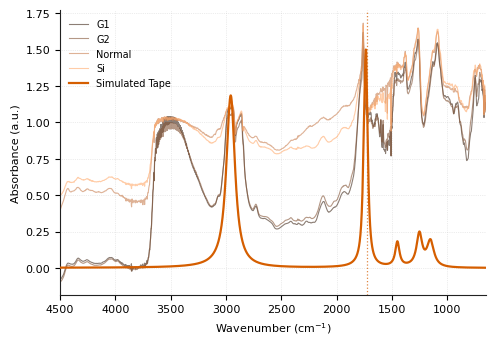

In [4]:
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def run_tape_overlay_pandas(data_folder, save_path="tape_simulation_overlay.pdf"):
    print(f"\n--- Starting Tape Simulation Overlay ---")
    
    wn_min = 650
    wn_max = 4500
    wn = np.linspace(wn_min, wn_max, 2500)

    # --- 1. Multi-Oscillator Transflection Model for Tape ---
    eps_inf = 2.25  
    thickness_cm = 40e-4  
    oscillators = [
        (2950, 0.050, 90, "C-H stretch"),
        (1730, 0.080, 35, "C=O stretch"),
        (1450, 0.015, 45, "C-H bend"),
        (1250, 0.035, 60, "C-O stretch"),
        (1150, 0.045, 75, "C-C skeletal"),
    ]

    eps = np.full_like(wn, eps_inf, dtype=complex)
    for w0, f, gamma, name in oscillators:
        eps += (f * w0**2) / (w0**2 - wn**2 - 1j * gamma * wn)

    n_complex = np.sqrt(eps)
    k_extinction = np.imag(n_complex)
    alpha = 4 * np.pi * wn * k_extinction
    sim_absorbance = alpha * (2 * thickness_cm)
    
    # Normalize simulation to roughly match the height of your experimental data (1.5 a.u.)
    sim_absorbance_norm = sim_absorbance / np.max(sim_absorbance) * 1.5

    # --- 2. Publication Styling ---
    rc_publication = {
        "font.family": "sans-serif",
        "font.size": 8,
        "axes.linewidth": 0.8,
        "axes.edgecolor": "#222222",
    }

    with mpl.rc_context(rc_publication):
        fig, ax = plt.subplots(figsize=(5.0, 3.5))

        # --- 3. Load Experimental Data (Using Your Exact Pandas Logic) ---
        search_pattern = os.path.join(data_folder, "*.[cC][sS][vV]")
        exp_files = sorted(glob.glob(search_pattern))
        
        print(f"Found {len(exp_files)} CSV file(s) in {data_folder}.")
        
        # Label mapping for clean legend names
        label_map = {
            "g1": "G1",
            "g2": "G2",
            "normal": "Normal",
            "si": "Si"
        }

        if exp_files:
            exp_colors = plt.cm.copper(np.linspace(0.2, 0.85, len(exp_files)))
            for fpath, col in zip(exp_files, exp_colors):
                fname = os.path.basename(fpath)
                
                # Strip extension and apply exact names from the map
                raw_name = fname.replace(".csv", "").replace(".CSV", "").lower()
                clean_label = label_map.get(raw_name, raw_name.title())
                
                try:
                    df = pd.read_csv(fpath, skiprows=4, sep=r"\s+")
                    spectrum = df.iloc[:, [0, 2]].to_numpy()
                    x_exp = spectrum[:, 0]
                    y_exp = spectrum[:, 1]
                    
                    mask = (x_exp >= wn_min) & (x_exp <= wn_max)
                    x_sub = x_exp[mask]
                    y_sub = y_exp[mask]
                    
                    if len(x_sub) > 0:
                        ax.plot(
                            x_sub,
                            y_sub,
                            label=clean_label,
                            color=col,
                            linewidth=0.8,
                            alpha=0.6,
                        )
                except Exception as e:
                    print(f" -> ERROR loading {fname}: {e}")

        # --- 4. Overlay Simulated Tape Profile ---
        ax.plot(
            wn,
            sim_absorbance_norm,
            label="Simulated Tape",
            color="#D55E00",
            linewidth=1.6,
            zorder=5,
        )

        ax.axvline(1730, color="#D55E00", linestyle=":", linewidth=0.9, alpha=0.75)

        # Aesthetics
        ax.set_xlim(wn_max, wn_min)  
        ax.set_xlabel(r"Wavenumber ($\mathrm{cm^{-1}}$)")
        ax.set_ylabel("Absorbance (a.u.)")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(True, linestyle=":", linewidth=0.5, color="#CCCCCC", alpha=0.7)
        
        # Moved legend to the upper left
        ax.legend(frameon=False, loc="upper left", fontsize=7.0)

        plt.tight_layout()
        
        # --- 5. Save and Show ---
        if save_path:
            fig.savefig(save_path, format="pdf", bbox_inches="tight")
            print(f"\nSaved figure as: {save_path}")
            
        plt.show()

# ==========================================
# PASTE YOUR FOLDER PATH HERE
# ==========================================
my_csv_folder = r"60826/nocover" 

if __name__ == "__main__":
    run_tape_overlay_pandas(data_folder=my_csv_folder, save_path="tape_simulation_overlay.pdf")